# Import Module

In [1]:
import pandas as pd
import numpy as np

# Mempersiapkan Data

In [2]:
# Daca data csv
df = pd.read_csv(r'E:\Tesis Yopi Andriyansah\Tesis-Yopi-Andriyansah-MTE26\Data/data_juni_ST2_7D_clean_new_yopi.csv')
df.head()
#E:/KP RAFI RIDHO RAMADHAN/data_juni_ST2_7D_clean.csv
#E:\Tesis Yopi Andriyansah\Tesis-Yopi-Andriyansah-MTE26\Data/data_juni_ST2_7D_clean_new_yopi.csv

,timestamp,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),timur (m/s),selatan (m/s),bawah (m/s),atas (m/s)
0,2024-06-10 13:06:01.353,100.829346,23.213638,37.528976,74.532692,27.232393,364.0,0,1943.793818,2.79,0.00,0.0,0.460000,4.60,0.00
1,2024-06-10 13:06:01.436,100.875145,27.721346,37.549667,74.512856,27.275118,363.0,0,1947.872620,2.79,0.87,0.0,0.483522,4.86,0.00
2,2024-06-10 13:06:01.600,100.876099,27.732904,37.537556,74.476234,27.275118,363.0,0,1946.915292,2.79,0.87,0.0,0.530000,4.60,0.28
3,2024-06-10 13:06:01.763,100.874657,27.744940,37.568340,74.431984,27.259096,363.0,0,1944.035748,2.79,0.87,0.0,0.530000,4.86,0.00
4,2024-06-10 13:06:01.926,100.874779,27.753908,37.621830,74.491493,27.301826,363.0,0,1950.191300,2.79,0.87,0.0,0.530000,4.86,0.00


In [3]:
# Mengubah "Timestamp" menjadi indeks
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index("timestamp")
df = df.sort_index()

In [4]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 14 columns):
 #   Column                             Dtype  
---  ------                             -----  
 0   Air Pressure (kPa)                 float64
 1   Air Temperature (Celcius)          float64
 2   Altitude (MSAL)                    float64
 3   Relatif Humidity (%)               float64
 4   Temperature (Celsius)              float64
 5   C02 mole fraction (µmol/mol_a)     float64
 6   CH4 mole fraction (µmol/mol_a)     int64  
 7   Water Vapor Mass Density (kg/m^3)  float64
 8   utara (m/s)                        float64
 9   barat (m/s)                        float64
 10  timur (m/s)                        float64
 11  selatan (m/s)                      float64
 12  bawah (m/s)                        float64
 13  atas (m/s)                         float64
dtypes: float64(13), int64(1)
memory usage: 222.6 MB


# Parameter Tekanan Udara

In [5]:
R = 8.314 # Konstanta gas universal (J/mol/K)
T = df["Temperature (Celsius)"] + 273.15 # Suhu (Kelvin) # sht85Temp
P = df["Air Pressure (kPa)"] * 1000 # Tekanan udara (Pascal) # bmp388Pressure
df['rho'] = P/(R*T) # Densitas udara (mol/m³)

df.head()

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),timur (m/s),selatan (m/s),bawah (m/s),atas (m/s),rho
timestamp,,,,,,,,,,,,,,,
2024-06-10 13:06:01.353,100.829346,23.213638,37.528976,74.532692,27.232393,364.0,0,1943.793818,2.79,0.00,0.0,0.460000,4.60,0.00,40.374063
2024-06-10 13:06:01.436,100.875145,27.721346,37.549667,74.512856,27.275118,363.0,0,1947.872620,2.79,0.87,0.0,0.483522,4.86,0.00,40.386658
2024-06-10 13:06:01.600,100.876099,27.732904,37.537556,74.476234,27.275118,363.0,0,1946.915292,2.79,0.87,0.0,0.530000,4.60,0.28,40.387039
2024-06-10 13:06:01.763,100.874657,27.744940,37.568340,74.431984,27.259096,363.0,0,1944.035748,2.79,0.87,0.0,0.530000,4.86,0.00,40.388616
2024-06-10 13:06:01.926,100.874779,27.753908,37.621830,74.491493,27.301826,363.0,0,1950.191300,2.79,0.87,0.0,0.530000,4.86,0.00,40.382921


# Parameter Angin

In [6]:
# Membuat parameter 'w'
df["w"] = df["atas (m/s)"] - df["bawah (m/s)"]


df.head(30)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),timur (m/s),selatan (m/s),bawah (m/s),atas (m/s),rho,w
timestamp,,,,,,,,,,,,,,,,
2024-06-10 13:06:01.353,100.829346,23.213638,37.528976,74.532692,27.232393,364.0,0,1943.793818,2.79,0.00,0.0,0.460000,4.60,0.00,40.374063,-4.60
2024-06-10 13:06:01.436,100.875145,27.721346,37.549667,74.512856,27.275118,363.0,0,1947.872620,2.79,0.87,0.0,0.483522,4.86,0.00,40.386658,-4.86
2024-06-10 13:06:01.600,100.876099,27.732904,37.537556,74.476234,27.275118,363.0,0,1946.915292,2.79,0.87,0.0,0.530000,4.60,0.28,40.387039,-4.32
2024-06-10 13:06:01.763,100.874657,27.744940,37.568340,74.431984,27.259096,363.0,0,1944.035748,2.79,0.87,0.0,0.530000,4.86,0.00,40.388616,-4.86
2024-06-10 13:06:01.926,100.874779,27.753908,37.621830,74.491493,27.301826,363.0,0,1950.191300,2.79,0.87,0.0,0.530000,4.86,0.00,40.382921,-4.86
2024-06-10 13:06:02.091,100.874000,27.758665,37.597103,74.485390,27.232393,363.0,0,1942.560187,2.79,0.00,0.0,0.530000,4.60,0.00,40.391944,-4.60
2024-06-10 13:06:02.254,100.876038,27.762419,37.553703,74.436562,27.275118,363.0,0,1945.878187,2.79,0.87,0.0,0.530000,4.86,0.00,40.387015,-4.86
2024-06-10 13:06:02.422,100.874970,27.761484,37.522923,74.384674,27.259096,363.0,0,1942.800096,2.79,0.87,0.0,0.530000,4.86,0.00,40.388741,-4.86
2024-06-10 13:06:02.583,100.874741,27.759705,37.512325,74.485390,27.275118,363.0,0,1947.154624,2.79,0.87,0.0,0.530000,4.60,0.00,40.386496,-4.60


# Menghitung Fluks

In [7]:
# Menentukan window waktu rolling mean selama 30 menit
rolling_window = '30min'

In [9]:
# Menghitung rata-rata bergerak dalam tiap window waktu
df['w_mean_30min'] = df['w'].rolling(rolling_window).mean()
df['c_mean_30min'] = df['C02 mole fraction (µmol/mol_a)'].rolling(rolling_window).mean() #co2


In [10]:
# Menghitung fluktuasi dengan reynold decomposistion
df['w_prime'] = df['w'] - df['w_mean_30min']
df['c_prime'] = df['C02 mole fraction (µmol/mol_a)'] - df['c_mean_30min'] #co2


df.head(50)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),timur (m/s),selatan (m/s),bawah (m/s),atas (m/s),rho,w,w_mean_30min,c_mean_30min,w_prime,c_prime
timestamp,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:06:01.353,100.829346,23.213638,37.528976,74.532692,27.232393,364.0,0,1943.793818,2.79,0.00,0.0,0.460000,4.60,0.00,40.374063,-4.60,-4.600000,364.000000,0.000000,0.000000
2024-06-10 13:06:01.436,100.875145,27.721346,37.549667,74.512856,27.275118,363.0,0,1947.872620,2.79,0.87,0.0,0.483522,4.86,0.00,40.386658,-4.86,-4.730000,363.500000,-0.130000,-0.500000
2024-06-10 13:06:01.600,100.876099,27.732904,37.537556,74.476234,27.275118,363.0,0,1946.915292,2.79,0.87,0.0,0.530000,4.60,0.28,40.387039,-4.32,-4.593333,363.333333,0.273333,-0.333333
2024-06-10 13:06:01.763,100.874657,27.744940,37.568340,74.431984,27.259096,363.0,0,1944.035748,2.79,0.87,0.0,0.530000,4.86,0.00,40.388616,-4.86,-4.660000,363.250000,-0.200000,-0.250000
2024-06-10 13:06:01.926,100.874779,27.753908,37.621830,74.491493,27.301826,363.0,0,1950.191300,2.79,0.87,0.0,0.530000,4.86,0.00,40.382921,-4.86,-4.700000,363.200000,-0.160000,-0.200000
2024-06-10 13:06:02.091,100.874000,27.758665,37.597103,74.485390,27.232393,363.0,0,1942.560187,2.79,0.00,0.0,0.530000,4.60,0.00,40.391944,-4.60,-4.683333,363.166667,0.083333,-0.166667
2024-06-10 13:06:02.254,100.876038,27.762419,37.553703,74.436562,27.275118,363.0,0,1945.878187,2.79,0.87,0.0,0.530000,4.86,0.00,40.387015,-4.86,-4.708571,363.142857,-0.151429,-0.142857
2024-06-10 13:06:02.422,100.874970,27.761484,37.522923,74.384674,27.259096,363.0,0,1942.800096,2.79,0.87,0.0,0.530000,4.86,0.00,40.388741,-4.86,-4.727500,363.125000,-0.132500,-0.125000
2024-06-10 13:06:02.583,100.874741,27.759705,37.512325,74.485390,27.275118,363.0,0,1947.154624,2.79,0.87,0.0,0.530000,4.60,0.00,40.386496,-4.60,-4.713333,363.111111,0.113333,-0.111111


In [11]:
# Fungsi untuk menghitung fluks per 30 menit
def calc_flux(group):
    group = group[['rho', 'w_prime', 'c_prime']].dropna()
    if len(group) < 100:
        return np.nan
    rho_mean = group['rho'].mean()
    cov_wc = np.mean(group['w_prime'] * group['c_prime'])
    return rho_mean * cov_wc



In [16]:
# Hitung flux Fc per 30 menit
Fc = df.resample('30min').apply(calc_flux)
Fc.name = 'Fc'

Fc.head(20)

timestamp
2024-06-10 13:00:00    -52.504728
2024-06-10 13:30:00   -176.171990
2024-06-10 14:00:00           NaN
2024-06-10 14:30:00           NaN
2024-06-10 15:00:00      1.687488
2024-06-10 15:30:00           NaN
2024-06-10 16:00:00     -0.032736
2024-06-10 16:30:00     -0.322412
2024-06-10 17:00:00     -0.017264
2024-06-10 17:30:00      0.172470
2024-06-10 18:00:00     -0.021504
2024-06-10 18:30:00     -0.186148
2024-06-10 19:00:00      0.039710
2024-06-10 19:30:00      0.080388
2024-06-10 20:00:00     -0.010792
2024-06-10 20:30:00      0.014315
2024-06-10 21:00:00      0.058880
2024-06-10 21:30:00      0.023602
2024-06-10 22:00:00     -0.046635
2024-06-10 22:30:00      0.084017
Freq: 30min, Name: Fc, dtype: float64

In [17]:
data_30min = df.resample('30min').mean(numeric_only=True)   #30T

data_30min.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),timur (m/s),selatan (m/s),bawah (m/s),atas (m/s),rho,w,w_mean_30min,c_mean_30min,w_prime,c_prime
timestamp,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,2064.145237,2.627372,0.482492,0.0,0.330069,5.893682,0.004946,40.450666,-5.888737,-6.059909,362.251085,0.171172,-2.214287
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.625080,1.098545,0.0,0.526104,4.973995,0.000757,40.367906,-4.973237,-5.793526,359.415772,0.820289,-5.322445
2024-06-10 14:00:00,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.620000,1.650000,0.0,0.498897,3.915409,0.000000,40.159169,-3.915409,-3.915409,351.000000,0.000000,0.000000
2024-06-10 14:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-06-10 15:00:00,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,2.620000,0.622967,0.0,0.450414,3.164459,0.063962,40.477373,-3.100497,-2.880785,352.206164,-0.219712,-0.264026
2024-06-10 15:30:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-06-10 16:00:00,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,2.620000,0.164091,0.0,0.464541,0.000000,0.001394,40.620141,0.001394,0.001671,367.036506,-0.000277,2.814349
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,2.620000,0.132783,0.0,0.467095,0.000000,0.000253,40.624493,0.000253,0.001265,370.821059,-0.001013,7.608350
2024-06-10 17:00:00,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,2.620000,0.159778,0.0,0.469285,0.000000,0.002884,40.689599,0.002884,0.003079,384.020427,-0.000196,1.203656


In [18]:
data_30min.isna().sum()

Air Pressure (kPa)                   2
Air Temperature (Celcius)            2
Altitude (MSAL)                      2
Relatif Humidity (%)                 2
Temperature (Celsius)                2
C02 mole fraction (µmol/mol_a)       2
CH4 mole fraction (µmol/mol_a)       2
Water Vapor Mass Density (kg/m^3)    2
utara (m/s)                          2
barat (m/s)                          2
timur (m/s)                          2
selatan (m/s)                        2
bawah (m/s)                          2
atas (m/s)                           2
rho                                  2
w                                    2
w_mean_30min                         2
c_mean_30min                         2
w_prime                              2
c_prime                              2
dtype: int64

In [19]:
# Isi data NaN dengan Interpolasi Time
data_30min_filled = data_30min.interpolate(method='time')

data_30min_filled.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),timur (m/s),selatan (m/s),bawah (m/s),atas (m/s),rho,w,w_mean_30min,c_mean_30min,w_prime,c_prime
timestamp,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,2064.145237,2.627372,0.482492,0.0,0.330069,5.893682,0.004946,40.450666,-5.888737,-6.059909,362.251085,0.171172,-2.214287
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.625080,1.098545,0.0,0.526104,4.973995,0.000757,40.367906,-4.973237,-5.793526,359.415772,0.820289,-5.322445
2024-06-10 14:00:00,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.620000,1.650000,0.0,0.498897,3.915409,0.000000,40.159169,-3.915409,-3.915409,351.000000,0.000000,0.000000
2024-06-10 14:30:00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,2.620000,1.136484,0.0,0.474656,3.539934,0.031981,40.318271,-3.507953,-3.398097,351.603082,-0.109856,-0.132013
2024-06-10 15:00:00,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,2.620000,0.622967,0.0,0.450414,3.164459,0.063962,40.477373,-3.100497,-2.880785,352.206164,-0.219712,-0.264026
2024-06-10 15:30:00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,2.620000,0.393529,0.0,0.457477,1.582229,0.032678,40.548757,-1.549551,-1.439557,359.621335,-0.109995,1.275161
2024-06-10 16:00:00,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,2.620000,0.164091,0.0,0.464541,0.000000,0.001394,40.620141,0.001394,0.001671,367.036506,-0.000277,2.814349
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,2.620000,0.132783,0.0,0.467095,0.000000,0.000253,40.624493,0.000253,0.001265,370.821059,-0.001013,7.608350
2024-06-10 17:00:00,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,2.620000,0.159778,0.0,0.469285,0.000000,0.002884,40.689599,0.002884,0.003079,384.020427,-0.000196,1.203656


In [20]:
# Gabungkan hasilnya
merged = data_30min_filled.join(Fc)

merged.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,selatan (m/s),bawah (m/s),atas (m/s),rho,w,w_mean_30min,c_mean_30min,w_prime,c_prime,Fc
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,2064.145237,2.627372,0.482492,...,0.330069,5.893682,0.004946,40.450666,-5.888737,-6.059909,362.251085,0.171172,-2.214287,-52.504728
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.625080,1.098545,...,0.526104,4.973995,0.000757,40.367906,-4.973237,-5.793526,359.415772,0.820289,-5.322445,-176.171990
2024-06-10 14:00:00,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.620000,1.650000,...,0.498897,3.915409,0.000000,40.159169,-3.915409,-3.915409,351.000000,0.000000,0.000000,NaN
2024-06-10 14:30:00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,2.620000,1.136484,...,0.474656,3.539934,0.031981,40.318271,-3.507953,-3.398097,351.603082,-0.109856,-0.132013,NaN
2024-06-10 15:00:00,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,2.620000,0.622967,...,0.450414,3.164459,0.063962,40.477373,-3.100497,-2.880785,352.206164,-0.219712,-0.264026,1.687488
2024-06-10 15:30:00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,2.620000,0.393529,...,0.457477,1.582229,0.032678,40.548757,-1.549551,-1.439557,359.621335,-0.109995,1.275161,NaN
2024-06-10 16:00:00,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,2.620000,0.164091,...,0.464541,0.000000,0.001394,40.620141,0.001394,0.001671,367.036506,-0.000277,2.814349,-0.032736
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,2.620000,0.132783,...,0.467095,0.000000,0.000253,40.624493,0.000253,0.001265,370.821059,-0.001013,7.608350,-0.322412
2024-06-10 17:00:00,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,2.620000,0.159778,...,0.469285,0.000000,0.002884,40.689599,0.002884,0.003079,384.020427,-0.000196,1.203656,-0.017264


In [21]:
# Isi data NaN dengan Interpolasi Time
final_flux = merged.interpolate(method='time')

final_flux.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,selatan (m/s),bawah (m/s),atas (m/s),rho,w,w_mean_30min,c_mean_30min,w_prime,c_prime,Fc
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,2064.145237,2.627372,0.482492,...,0.330069,5.893682,0.004946,40.450666,-5.888737,-6.059909,362.251085,0.171172,-2.214287,-52.504728
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.625080,1.098545,...,0.526104,4.973995,0.000757,40.367906,-4.973237,-5.793526,359.415772,0.820289,-5.322445,-176.171990
2024-06-10 14:00:00,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.620000,1.650000,...,0.498897,3.915409,0.000000,40.159169,-3.915409,-3.915409,351.000000,0.000000,0.000000,-116.885497
2024-06-10 14:30:00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,2.620000,1.136484,...,0.474656,3.539934,0.031981,40.318271,-3.507953,-3.398097,351.603082,-0.109856,-0.132013,-57.599005
2024-06-10 15:00:00,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,2.620000,0.622967,...,0.450414,3.164459,0.063962,40.477373,-3.100497,-2.880785,352.206164,-0.219712,-0.264026,1.687488
2024-06-10 15:30:00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,2.620000,0.393529,...,0.457477,1.582229,0.032678,40.548757,-1.549551,-1.439557,359.621335,-0.109995,1.275161,0.827376
2024-06-10 16:00:00,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,2.620000,0.164091,...,0.464541,0.000000,0.001394,40.620141,0.001394,0.001671,367.036506,-0.000277,2.814349,-0.032736
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,2.620000,0.132783,...,0.467095,0.000000,0.000253,40.624493,0.000253,0.001265,370.821059,-0.001013,7.608350,-0.322412
2024-06-10 17:00:00,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,2.620000,0.159778,...,0.469285,0.000000,0.002884,40.689599,0.002884,0.003079,384.020427,-0.000196,1.203656,-0.017264


In [22]:
# Konversi satuan agar menjadi ton/Ha/s
final_flux['ton_hectare_flux'] = final_flux['Fc'] * 44.001 * 1e-8


final_flux.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,bawah (m/s),atas (m/s),rho,w,w_mean_30min,c_mean_30min,w_prime,c_prime,Fc,ton_hectare_flux
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,2064.145237,2.627372,0.482492,...,5.893682,0.004946,40.450666,-5.888737,-6.059909,362.251085,0.171172,-2.214287,-52.504728,-2.310261e-05
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.625080,1.098545,...,4.973995,0.000757,40.367906,-4.973237,-5.793526,359.415772,0.820289,-5.322445,-176.171990,-7.751744e-05
2024-06-10 14:00:00,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.620000,1.650000,...,3.915409,0.000000,40.159169,-3.915409,-3.915409,351.000000,0.000000,0.000000,-116.885497,-5.143079e-05
2024-06-10 14:30:00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,2.620000,1.136484,...,3.539934,0.031981,40.318271,-3.507953,-3.398097,351.603082,-0.109856,-0.132013,-57.599005,-2.534414e-05
2024-06-10 15:00:00,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,2.620000,0.622967,...,3.164459,0.063962,40.477373,-3.100497,-2.880785,352.206164,-0.219712,-0.264026,1.687488,7.425115e-07
2024-06-10 15:30:00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,2.620000,0.393529,...,1.582229,0.032678,40.548757,-1.549551,-1.439557,359.621335,-0.109995,1.275161,0.827376,3.640536e-07
2024-06-10 16:00:00,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,2.620000,0.164091,...,0.000000,0.001394,40.620141,0.001394,0.001671,367.036506,-0.000277,2.814349,-0.032736,-1.440436e-08
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,2.620000,0.132783,...,0.000000,0.000253,40.624493,0.000253,0.001265,370.821059,-0.001013,7.608350,-0.322412,-1.418646e-07
2024-06-10 17:00:00,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,2.620000,0.159778,...,0.000000,0.002884,40.689599,0.002884,0.003079,384.020427,-0.000196,1.203656,-0.017264,-7.596422e-09


In [23]:
# Konversi satuan agar menjadi ton/Ha/year
sec_to_year = 31557600
ton_flux_year = final_flux['ton_hectare_flux'] * sec_to_year
final_flux['ton_flux_year'] = ton_flux_year


final_flux.head(20)

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),...,atas (m/s),rho,w,w_mean_30min,c_mean_30min,w_prime,c_prime,Fc,ton_hectare_flux,ton_flux_year
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 13:00:00,100.827531,26.376570,41.500479,81.746555,26.658762,360.036798,0.0,2064.145237,2.627372,0.482492,...,0.004946,40.450666,-5.888737,-6.059909,362.251085,0.171172,-2.214287,-52.504728,-2.310261e-05,-729.062785
2024-06-10 13:30:00,100.775620,27.077859,45.841672,84.466928,27.118138,354.093327,0.0,2189.055824,2.625080,1.098545,...,0.000757,40.367906,-4.973237,-5.793526,359.415772,0.820289,-5.322445,-176.171990,-7.751744e-05,-2446.264275
2024-06-10 14:00:00,100.800875,26.889366,45.717457,81.821922,28.754484,351.000000,0.0,2320.151137,2.620000,1.650000,...,0.000000,40.159169,-3.915409,-3.915409,351.000000,0.000000,0.000000,-116.885497,-5.143079e-05,-1623.032223
2024-06-10 14:30:00,100.812566,26.529459,43.747313,86.619745,27.602548,351.471069,0.0,2301.563549,2.620000,1.136484,...,0.031981,40.318271,-3.507953,-3.398097,351.603082,-0.109856,-0.132013,-57.599005,-2.534414e-05,-799.800171
2024-06-10 15:00:00,100.824257,26.169551,41.777170,91.417568,26.450613,351.942138,0.0,2282.975962,2.620000,0.622967,...,0.063962,40.477373,-3.100497,-2.880785,352.206164,-0.219712,-0.264026,1.687488,7.425115e-07,23.431881
2024-06-10 15:30:00,100.894707,25.843265,35.889712,90.086437,26.132715,360.896496,0.0,2211.118403,2.620000,0.393529,...,0.032678,40.548757,-1.549551,-1.439557,359.621335,-0.109995,1.275161,0.827376,3.640536e-07,11.488657
2024-06-10 16:00:00,100.965157,25.516978,30.002255,88.755306,25.814818,369.850854,0.0,2139.260845,2.620000,0.164091,...,0.001394,40.620141,0.001394,0.001671,367.036506,-0.000277,2.814349,-0.032736,-1.440436e-08,-0.454567
2024-06-10 16:30:00,100.958938,25.461470,30.522013,89.676946,25.764373,378.429409,0.0,2155.392429,2.620000,0.132783,...,0.000253,40.624493,0.000253,0.001265,370.821059,-0.001013,7.608350,-0.322412,-1.418646e-07,-4.476907
2024-06-10 17:00:00,101.020787,25.125617,25.356869,91.423566,25.468921,385.224083,0.0,2161.311639,2.620000,0.159778,...,0.002884,40.689599,0.002884,0.003079,384.020427,-0.000196,1.203656,-0.017264,-7.596422e-09,-0.239725


# Visualisasi Data

In [24]:
import matplotlib.pyplot as plt

**Fluks Karbon (umol/m^2/s)**

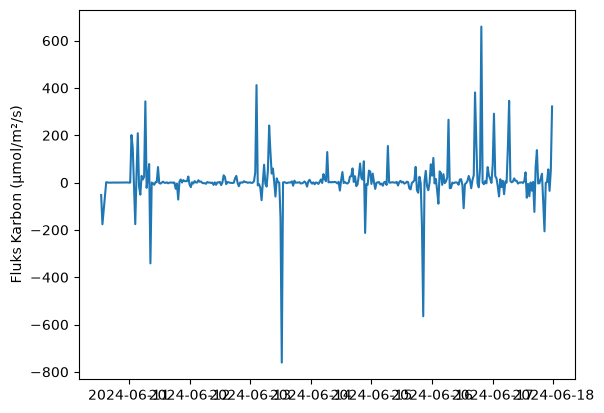

In [25]:
# Menampilkan visualisasi 
plt.plot(final_flux['Fc'])
plt.ylabel('Fluks Karbon (μmol/m²/s)')
plt.show()

**Fluks Karbon (ton/ha/s)**

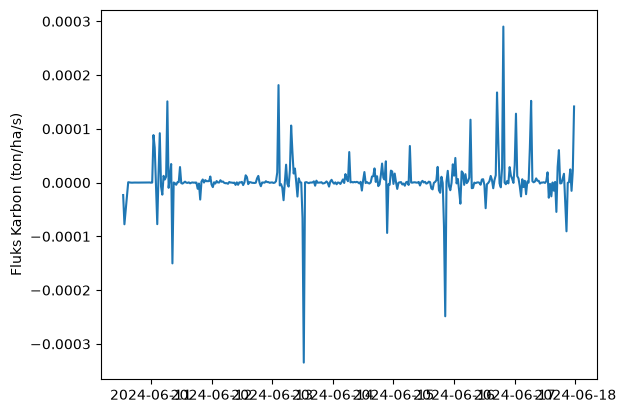

In [26]:
# Menampilkan visualisasi 
plt.plot(final_flux['ton_hectare_flux'])
plt.ylabel('Fluks Karbon (ton/ha/s)')
plt.show()

**Fluks Karbon (ton/ha/year)**

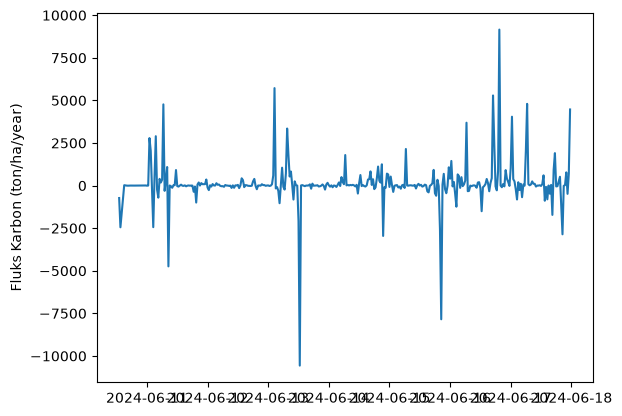

In [27]:
# Menampilkan visualisasi 
plt.plot(final_flux['ton_flux_year'])
plt.ylabel('Fluks Karbon (ton/ha/year)')
plt.show()

**Visualisasi jumlah nilai positif dan negatif data ECS**

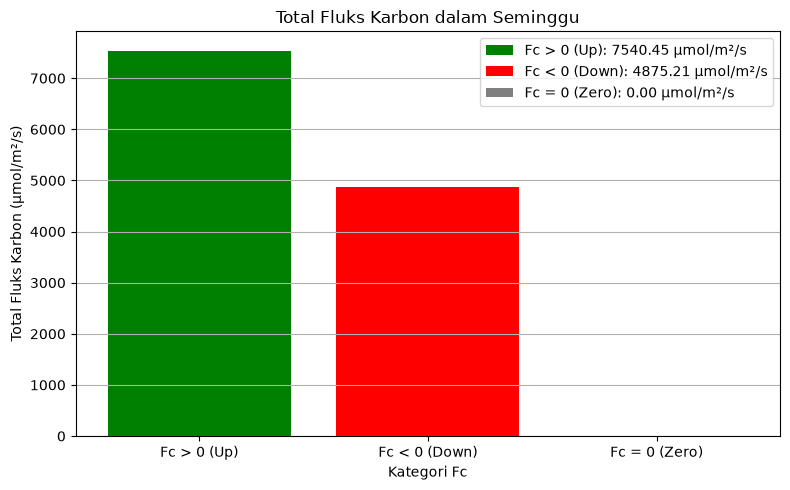

In [28]:
# Ambil kolom Fc
Fc = final_flux['Fc']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = Fc[Fc > 0].sum()
Fc_neg_sum = -Fc[Fc < 0].sum()  # Ambil nilai absolut
Fc_zero_sum = Fc[Fc == 0].sum()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


**Visualisasi Licor**

In [30]:
licor = pd.read_csv(r"E:\Tesis Yopi Andriyansah\Tesis-Yopi-Andriyansah-MTE26\Data\Data Sources/data.csv")
#E:\Tesis Yopi Andriyansah\Tesis-Yopi-Andriyansah-MTE26\Data\Data Sources
#E:/KP RAFI RIDHO RAMADHAN/Data/data.csv
licor.head()

,fluks_licor
0,120.188
1,172.375
2,677.048
3,16.939
4,164.982


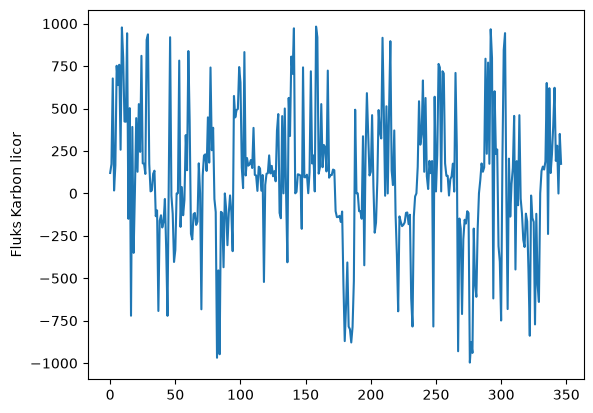

In [31]:
# Menampilkan visualisasi 
plt.plot(licor['fluks_licor'])
plt.ylabel('Fluks Karbon licor')
plt.show()

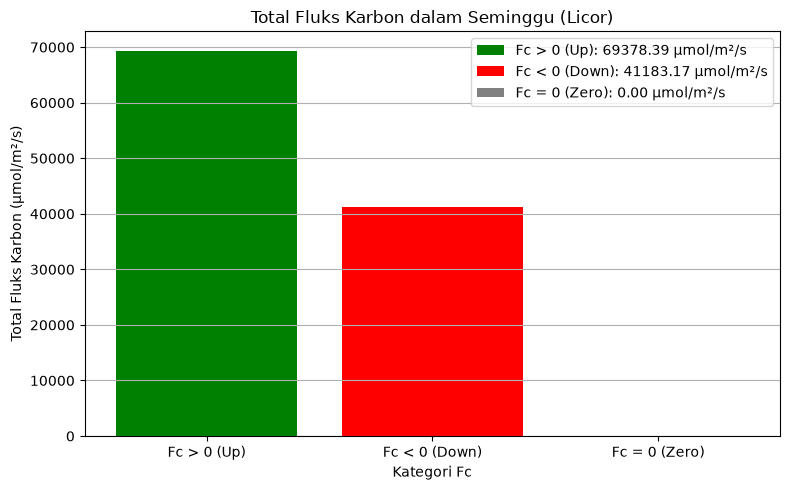

In [32]:

licor = licor['fluks_licor']


# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = licor[licor > 0].sum()
Fc_neg_sum = -licor[licor < 0].sum()  # Ambil nilai absolut
Fc_zero_sum = licor[licor == 0].sum()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu (Licor)')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Visualisasi Perhitungan Fluks Kak Irgi** 

- Catatan:
Perhitungan fluks milik kak irgi tidak melakuan perhitungan kovarians antara w_prime dengan c_prime per 30 menit 

In [103]:
kak_irgi = pd.read_csv("E:/KP RAFI RIDHO RAMADHAN/Fec_perdetik.csv")

kak_irgi.head(20)

,timestamp,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w,w_30m,w_aksen,p_H2O_sat,RH_decimal,p_H2O,x_H2O,co2_dry,co2_dry_30m,co2_dry_aksen,dry_pressure,Fec
0,2024-06-10 00:06:01,94.939728,93.432518,25.907911,457.000000,0.025559,0.000000,-0.025559,-0.017209,-0.008350,3.336997,0.934325,3.117843,0.033156,472.677872,473.764525,-1.086653,91.821885,0.006358
1,2024-06-10 00:06:02,99.238525,93.438876,25.907020,457.000000,0.079437,0.046667,-0.032771,-0.002278,-0.030493,3.336820,0.934389,3.117888,0.031418,471.823902,472.342324,-0.518422,96.120637,0.002544
2,2024-06-10 00:06:03,98.883162,93.424126,25.911472,457.000000,0.016418,0.000000,-0.016418,-0.029582,0.013164,3.337698,0.934241,3.118216,0.031535,471.880556,472.133926,-0.253371,95.764946,-0.000982
3,2024-06-10 00:06:04,99.118097,93.453880,25.930165,457.000000,0.020834,0.000000,-0.020834,-0.022998,0.002164,3.341399,0.934539,3.122667,0.031505,471.866002,472.058647,-0.192645,95.995429,-0.000030
4,2024-06-10 00:06:05,99.003197,93.415951,25.910198,457.714286,0.162485,0.000000,-0.162485,-0.044941,-0.117544,3.337445,0.934160,3.117706,0.031491,472.596863,472.088477,0.508386,95.885491,-0.024127
5,2024-06-10 00:06:06,99.142072,93.411410,25.909245,458.000000,0.111252,0.000000,-0.111252,-0.065835,-0.045418,3.337258,0.934114,3.117379,0.031444,472.868822,472.237377,0.631445,96.024693,-0.013174
6,2024-06-10 00:06:07,99.055558,93.436078,25.913697,458.000000,0.033434,0.000000,-0.033434,-0.062606,0.029171,3.338137,0.934361,3.119025,0.031488,472.890362,472.337360,0.553002,95.936533,0.006826
7,2024-06-10 00:06:08,99.053024,93.433790,25.927940,458.000000,0.035076,0.000000,-0.035076,-0.058215,0.023139,3.340954,0.934338,3.121580,0.031514,472.903242,472.410965,0.492277,95.931444,0.004925
8,2024-06-10 00:06:09,99.076754,93.412427,25.932391,458.000000,0.230730,0.000000,-0.230730,-0.073772,-0.156958,3.341835,0.934124,3.121689,0.031508,472.900135,472.468057,0.432079,95.955066,-0.028317
9,2024-06-10 00:06:10,99.259235,93.421328,25.918147,458.000000,0.139412,0.000000,-0.139412,-0.079761,-0.059651,3.339017,0.934213,3.119353,0.031426,472.860331,472.510399,0.349932,96.139881,-0.008171


In [104]:
kak_irgi.describe()

,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w,w_30m,w_aksen,p_H2O_sat,RH_decimal,p_H2O,x_H2O,co2_dry,co2_dry_30m,co2_dry_aksen,dry_pressure,Fec
count,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06,7.367170e+06
mean,1.009613e+02,8.573494e+01,2.690145e+01,4.981271e+02,5.216584e+00,3.171772e-01,-5.133313e+00,-5.128573e+00,-4.739917e-03,3.596089e+00,8.573494e-01,3.017808e+00,2.989401e-02,5.133015e+02,5.131856e+02,1.159007e-01,9.794351e+01,4.094594e-03
std,1.193277e+00,1.332746e+01,3.236048e+00,1.108315e+02,3.705696e+00,2.083233e-01,3.822088e+00,3.792979e+00,6.195394e-01,7.132762e-01,1.332746e-01,4.460822e-01,4.375573e-03,1.132934e+02,1.130401e+02,1.457788e+01,1.263462e+00,2.882197e+00
min,7.782306e+01,3.677751e+01,1.992371e+01,3.063333e+02,0.000000e+00,0.000000e+00,-1.398877e+01,-1.379000e+01,-8.997354e+00,2.322443e+00,3.677751e-01,1.436439e+00,1.397499e-02,3.165822e+02,3.191666e+02,-1.760264e+02,7.476968e+01,-2.935620e+01
25%,9.994669e+01,7.556894e+01,2.421225e+01,4.080000e+02,5.816081e-01,1.985714e-01,-8.424367e+00,-8.379404e+00,-8.976606e-02,3.016259e+00,7.556894e-01,2.823604e+00,2.796248e-02,4.216516e+02,4.213837e+02,-4.922408e+00,9.691777e+01,-1.775641e-01
50%,1.009616e+02,9.113196e+01,2.584649e+01,4.680000e+02,6.081183e+00,2.800000e-01,-6.081183e+00,-6.089898e+00,0.000000e+00,3.324876e+00,9.113196e-01,2.990025e+00,2.980341e-02,4.820370e+02,4.827190e+02,1.115905e-02,9.786552e+01,0.000000e+00
75%,1.019911e+02,9.715623e+01,2.955215e+01,5.717143e+02,8.424371e+00,4.133333e-01,-5.139505e-01,-4.642822e-01,9.652047e-02,4.128847e+00,9.715623e-01,3.168495e+00,3.153200e-02,5.886150e+02,5.881232e+02,4.829630e+00,9.887474e+01,1.788350e-01
max,1.037928e+02,1.001948e+02,3.763256e+01,9.690000e+02,1.398877e+01,4.032857e+00,4.032857e+00,1.131600e+00,1.049082e+01,6.490913e+00,1.001948e+00,5.391932e+00,5.390889e-02,9.915884e+02,9.688768e+02,1.784438e+02,1.018848e+02,2.941038e+01


In [105]:
# Mengubah "Timestamp" menjadi indeks
kak_irgi['timestamp'] = pd.to_datetime(kak_irgi['timestamp'])
kak_irgi = kak_irgi.set_index("timestamp")
kak_irgi = kak_irgi.sort_index()

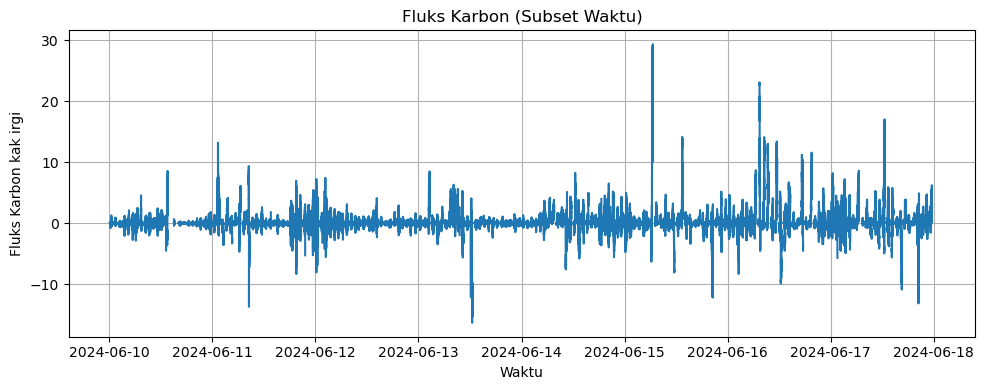

In [106]:
# Tentukan rentang waktu
start_time = '2024-06-10 00:06:01'
end_time   = '2024-06-18 00:06:01'

# Filter data sesuai rentang
filtered = kak_irgi.loc[start_time:end_time]

# Tampilkan plot
plt.figure(figsize=(10, 4))
plt.plot(filtered['Fec'])
plt.ylabel('Fluks Karbon kak irgi')
plt.xlabel('Waktu')
plt.title('Fluks Karbon (Subset Waktu)')
plt.grid(True)
plt.tight_layout()
plt.show()

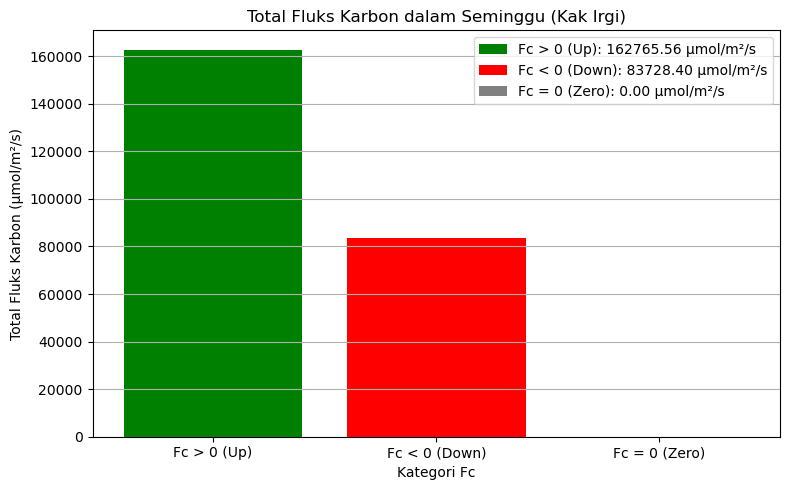

In [118]:
kakirgi = filtered['Fec']

# Hitung total nilai Fc untuk masing-masing kategori
Fc_pos_sum = kakirgi[kakirgi > 0].sum()
Fc_neg_sum = -kakirgi[kakirgi < 0].sum()  # Ambil nilai absolut
Fc_zero_sum = kakirgi[kakirgi == 0].sum()

# Data untuk bar chart
labels = ['Fc > 0 (Up)', 'Fc < 0 (Down)', 'Fc = 0 (Zero)']
sums = [Fc_pos_sum, Fc_neg_sum, Fc_zero_sum]
colors = ['green', 'red', 'gray']

# Plot bar chart
plt.figure(figsize=(8, 5))

bars = []
legend_labels = []

# Buat bar satu per satu dan kaitkan dengan labelnya
for label, total, color in zip(labels, sums, colors):
    bar = plt.bar(label, total, color=color, label=f"{label}: {total:.2f} μmol/m²/s")
    bars.append(bar)

# Tambahkan legenda (dari label di setiap bar)
plt.legend(loc='upper right')

# Tambahan info
plt.title('Total Fluks Karbon dalam Seminggu (Kak Irgi)')
plt.ylabel('Total Fluks Karbon (μmol/m²/s)')
plt.xlabel('Kategori Fc')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Menyimpan Data

In [125]:
# Simpan data ke csv
final_flux.to_csv('E:/KP RAFI RIDHO RAMADHAN/Hasil/final_data_flux.csv')